# Lesson 1. What is Gaussian Splatting, and what problem does it solve?

[Course outline](../../README.md) · [Русский](../ru/lesson-01.ipynb) · [Next lesson: one Gaussian on a line](lesson-02.ipynb)

We have a few photographs of a mug from different sides. The idea is to rotate it on a screen and look from a place where the camera **never stood**. The photographs are there. What would turn them into that kind of viewer?

We will start by rotating a small scene, taking it apart, changing a few numbers, and watching what happens to the image. Then we will follow the path from photographs to a finished model: what it stores, how training finds those values, and what the program does when we simply move the camera.

Along the way, we will look at a limitation that is easy to miss: being able to look behind an object does not mean we have discovered what its back really looks like.

No matrices or derivatives are needed yet. First, let us see what we are working with. In lesson 2, we will take one soft spot and work through its mathematics one operation at a time.

## 1. A Small Scene

We will start with a colored sphere above a plane. It is a small scene: **192 Gaussians**, with 128 on the sphere and 64 on the plane. Their positions, shapes, and colors are already specified in the code. Nothing has been trained from photographs here; this example lets us explore how the pieces work.

The camera is simplified too: distant objects do not shrink with perspective as they would in an ordinary photograph. This is an **orthographic** camera, with parallel projection directions. It makes the shapes easier to examine at first. We will introduce perspective and full rendering later.

To decide which footprint goes over another, the viewer compares the depths of their centers. That ordering can be wrong when shapes intersect in complicated ways. It is enough for our first experiments; we will return to overlap later.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from IPython.display import display

course_root = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "course_demos.py").is_file()),
    None,
)
if course_root is None:
    raise FileNotFoundError(
        "Open this notebook from inside the downloaded course folder."
    )
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from course_demos import scene_overview, scene_lab, coverage_figure, pipeline_figure
LANG = "en"

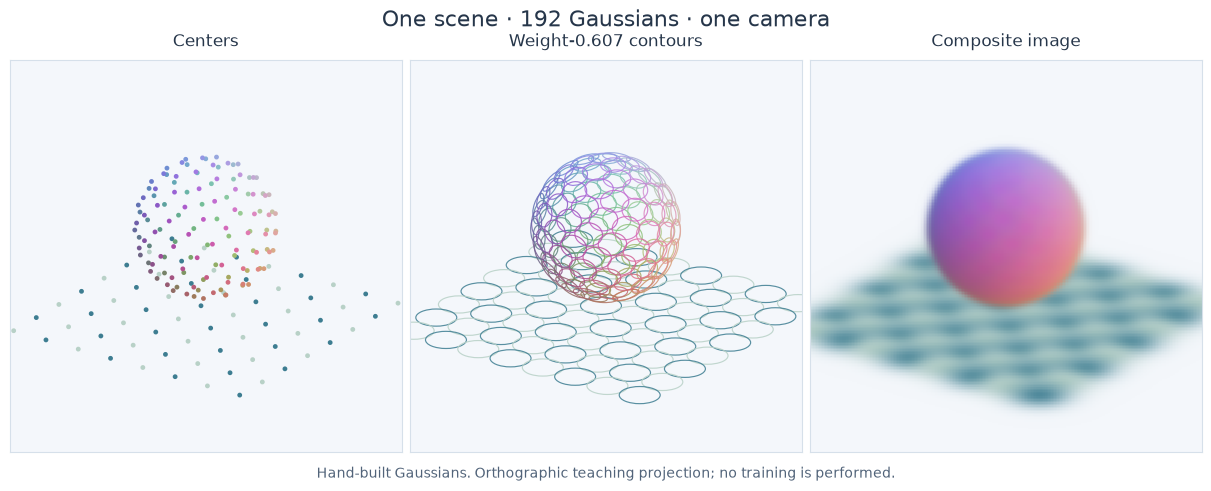

In [2]:
display(scene_overview(language=LANG))

These are three views of **the same data from the same viewpoint**. Each mode adds something:

| Mode | What is shown | What to look for |
|---|---|---|
| **Centers** | The position of each Gaussian | Gaps remain between the points. The size and softness of each footprint are still hidden. |
| **Contours** | A line at the same influence level around each Gaussian | Size and orientation are now visible. Influence continues beyond the contour, growing weaker. |
| **Composite image** | Soft colored footprints that overlap | The contributions combine into a more continuous image. |

Here, each contour is drawn where the footprint's weight is about **61% of its weight at the center**. We use the same level for every Gaussian so we can compare their shapes. In the next lesson, we will unpack what this weight means and how to calculate it.

Switching modes has not removed any centers. We are displaying the same collection of numbers in different ways.

In [3]:
display(scene_lab(language=LANG))

## 2. What Changes as the Camera and Parameters Move

Five changes are easy to follow in the image.

1. **Three modes with a fixed camera.** The plane has gaps between its centers. In Composite image mode, contributions around the existing centers fill those gaps.
2. **Camera orbit and view elevation.** The first slider takes the camera around the scene; the second changes the view from above to a view from the side. The plane looks broad from one direction and almost like a strip from another. The scene itself has stayed the same.
3. **One Gaussian in isolation.** The “Only the selected Gaussian” switch leaves one element on screen. Its number is called its index: its place in a list. That number does not inherently tell the program “chair,” “wall,” or “sphere.” Its contour shows the shape; Composite image mode shows its soft color contribution.
4. **Opacity 0, about 0.5, and 1.** In Composite image mode, zero makes the color contribution disappear. A larger value makes it stronger. In Centers mode, the point is still there because the element remains in the data.
5. **The whole scene and Reset.** Among all the other Gaussians, a change to one element can be easy to miss. Reset brings back the original parameters and viewpoint, giving the experiment the same starting image again.

We have already produced several different images without training anything. Each camera movement asked the program to compute another view of the same collection of elements.

## 3. Where does a new view come from?

Back to the mug. In the front photograph, the handle is on the right. From the other side of the table, it may appear on the left or disappear behind the body. Stretching the first photograph cannot give us those changes: it only records pixel colors from one viewpoint.

A photograph is a flat grid of colored pixels. Each pixel gives a color at one location **in that photograph**. That value alone does not tell us what a camera would see after moving one step to the left.

We therefore need a **scene representation**: data from which we can build images for different cameras. Building an image is called **rendering**. When we choose a camera position absent from the input photographs, we are doing **novel-view synthesis**.

In Gaussian Splatting, those data are a collection of Gaussians. The renderer takes their parameters and assembles an image for the chosen camera. Reconstruction fits the parameters to the photographs so that views from the input cameras increasingly resemble the original images.

Matching the photographs is already useful. How accurately the model describes the whole scene, including hidden surfaces, is something we still need to check. We will return to that when we discuss unseen sides.

## 4. What does one Gaussian store?

A soft spot of paint gives us a useful first picture: it can move, stretch, rotate, or become more noticeable. In 3D, we have a distribution of influence in space; projecting it produces a footprint on the screen. Paint is a useful analogy for the softness. It does not imply liquid behavior or a hard shell.

Each selected element has a card with its parameters. The Sphere and Plane labels were assigned manually when the example was built. No object recognition was needed to produce those labels.

Now let us examine four groups of properties. We will use simple numbers below, so they may differ from the selected element's values in the card.

### Position: where we put the center

On a plane, a position needs two coordinates; in space, it needs three. For example, **(0, 0, 1)**. In our experiment's coordinates, that means zero displacement along both directions of the plane and a height of 1 above it. Here, the vertical direction is called **z**; other programs may arrange their axes differently. The unit is arbitrary, so 1 does not necessarily mean one meter.

The Gaussian's weight is greatest at its center. Moving the center moves the entire distribution with it.

### Shape: which way to stretch it

An ordinary balloon and a flattened one make a useful comparison. The second can spread influence widely along a surface and narrowly across it. Rotation sets the directions in which it stretches.

For example, scales **(0.2, 0.2, 0.2)** are equal along the Gaussian's three local directions. Increasing the first to **0.4** makes the distribution wider in that direction. There is still no hard outer edge: influence gradually fades as we move away from the center.

In lesson 2, we will first explore one such scale on a line. Then we will add a second direction, build a footprint on a plane, and return to 3D.

### Color: what color the footprint adds

Our example stores color as three **RGB** components: red, green, and blue. Each ranges from 0 to 1. Then **(1, 0, 0)** gives red, **(0, 1, 0)** gives green, and **(1, 1, 1)** gives white.

Each Gaussian in this scene has a constant color. In full 3DGS, color can depend on viewing direction. That helps describe, for example, a shiny object's visible color changing as we walk around it. We will reach that color representation in lesson 15.

### Opacity: how noticeable its contribution is

The opacity slider ranges from **0 to 1**. At 0, the Gaussian adds nothing to the image's color. A larger value makes its contribution stronger.

Even with opacity **1**, the footprint stays soft. Influence is stronger at the center and weaker farther away; the entire footprint does not become an opaque plate. Neighboring elements and their overlap order also affect the final color.

That is why the control is called **opacity**: a larger number means a stronger contribution. Calling it transparency would suggest the opposite direction.

## 5. Why build a scene from many footprints?

One soft footprint only gets us so far. Several well-placed Gaussians can describe a color transition, an edge, or a surface region. Our sphere is built from many such elements, although no individual element inherently knows it is “part of a sphere.”

In isolation, one Gaussian describes very little. Once the rest of the scene returns, that same element becomes part of a surface.

It is tempting to jump from this to “add more Gaussians, get a better image.” So far, though, we have only added parameters to adjust. An accurate image needs suitable positions, shapes, and other values, enough observations, and a training process that can fit them.

A million randomly scattered Gaussians will not assemble themselves into an accurate room. There is no universal element count that makes every scene photorealistic.

The viewer lets us see the elements working together. The next course block will explore how to find their positions and shapes from images.

## 6. From photographs to a finished model

Our scene had a convenient starting point: all the parameters were already in the code. For a real object, we still need to find them. Let us follow where they come from when we start with photographs.

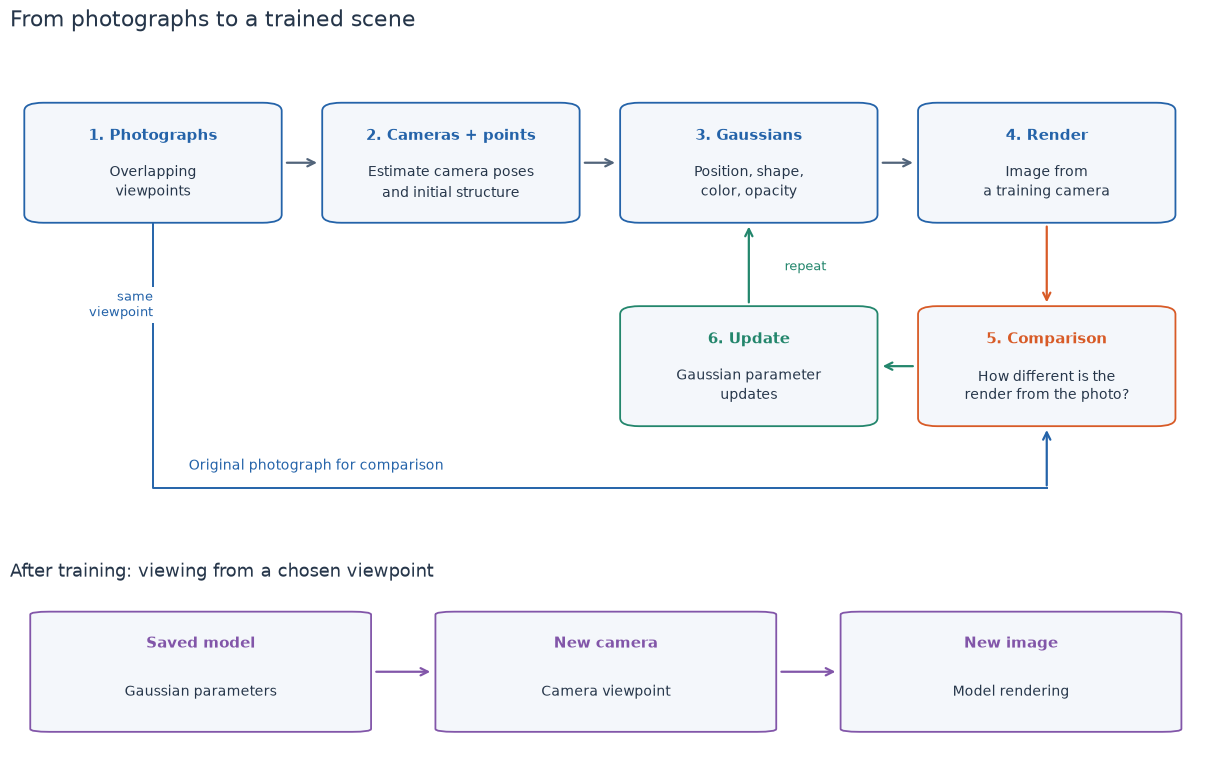

In [4]:
display(pipeline_figure(language=LANG))

| Stage | What we start with | What we get |
|---|---|---|
| **Capture** | A static scene and a camera | Photographs from different positions with shared regions of the scene |
| **Camera and point reconstruction** | Photographs with common visible details | Estimated camera parameters and a sparse point cloud; COLMAP often does this work |
| **Gaussian initialization** | Initial points and associated information | A first collection of Gaussians to begin training |
| **Training** | Gaussians, cameras, and input photographs | Adjusted parameters whose rendered images match the photographs more closely |
| **Viewing** | A saved model and a chosen camera | An image from the requested viewpoint |

Camera positions also have to be estimated. Errors at that stage make it harder for training to bring the model into agreement with the photographs.

### What training does

We place a virtual camera at the position of one input photograph and render the current model. Now we can place the two images side by side: where does the color already match, where is the object slightly displaced, and where has a detail disappeared?

We turn those differences into a numerical error. The algorithm changes parameters to reduce it, then takes another viewpoint and repeats the comparison. Basic 3DGS also adds and removes Gaussians. Adjusting existing elements and changing the number of elements are two related parts of the process.

The sequence is: **render an image → compare it with the photograph → adjust the parameters → repeat**. In lessons 6–9, we will calculate an error ourselves and work through an update with actual numbers. Full 3D training and changes to the Gaussian count come in lessons 16–17.

### What happens when we just view the model

During viewing, the parameters have already been found and saved. After the camera moves, the renderer uses those parameters to compute the next frame. It does not have to return to the photographs and train the model again after every turn. Training time and viewing speed are therefore separate measurements.

The [original 3DGS project page](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) has real reconstructions and comparisons with reference images. Our sphere and plane are still a manually built example for exploring the parameters; those reconstructions show the result of training from photographs.

In Visual Comparisons on the project page, Ours and Ground Truth show the method's result and a reference for the same viewpoint. Edges, fine textures, and highlights reveal which details match and which differ. Ground Truth is the reference for comparison; the label alone does not tell us that this particular frame was used for training. This is an extra experiment. The main lesson exercises work locally.

## 7. What about the side nobody photographed?

Let us return to the limitation from the beginning. The next diagram shows an object and the surrounding cameras from above, making each camera's visible area easier to follow. It does not simulate training or reconstruction quality.

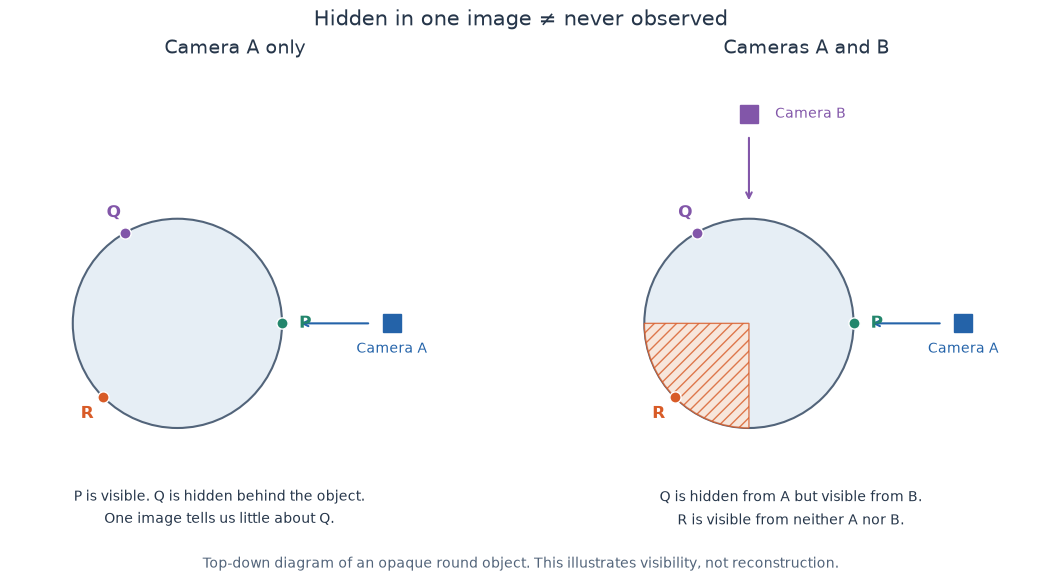

In [5]:
display(coverage_figure(language=LANG))

There are three cases in the diagram:

1. **The region is visible to camera A.** Its photograph already contains an observation of that region.
2. **The region is hidden from A but visible to camera B.** The second photograph adds something the first one is missing.
3. **The region is hidden from both cameras.** These observations do not directly tell us what it looks like.

Suppose we have two boxes with identical fronts. One has a red back; the other has a blue back. The camera records only the fronts, without capturing either back directly or through reflections. The photographs will be identical. They cannot tell us which color was behind either box.

The program can still draw a back wall. To check its color, though, we need an observation from behind. If we assume a color instead, that assumption brings in information from elsewhere; it did not come from the input photographs.

New viewpoints are not all hopeless. We can move the camera to a new position and see a surface already well covered by other photographs. Difficulties arise where observations are scarce or inconsistent.

Our example defines the whole sphere, so the program knows its back too. We can freely orbit it, but that has not tested the recovery of surfaces absent from every photograph.

## 8. Other ways to store a scene

We can now compare Gaussian Splatting with other approaches using the same question each time: **what is stored, and how does it become an image?**

| Representation | What it stores | What to remember |
|---|---|---|
| **Polygon mesh** | Vertices and faces, usually with materials or textures | The surface is explicit, making it useful for editing and interaction. An artist or an image-reconstruction algorithm can build it. |
| **Voxels** | Values in cells of a three-dimensional grid | Space is divided into cells, like a volumetric version of pixels. A dense grid grows quickly with resolution; sparse versions store only the needed parts. |
| **Point cloud** | Point coordinates, sometimes with color and other attributes | Useful for storing measurements and initial geometry. The viewer decides how to display the points. |
| **NeRF and related methods** | In the original NeRF, density depends on position; color also depends on viewing direction | A neural network computes these values in the original NeRF. Other methods change both the representation and computation, so their speeds differ. |
| **Gaussian Splatting** | A collection of Gaussians with adjustable parameters | Individual elements are projected and blended. Each can be inspected, but its relationship to an entire object still needs to be established. |

Each approach has different variants. For example, [Instant-NGP](https://nvlabs.github.io/instant-ngp/) is a useful reason not to label the entire NeRF family “always slow.”

The original 3DGS experiments combined high-quality images with fast rendering. For any new scene, quality and speed still need to be measured: the data, implementation, image resolution, work per frame, and computer all affect the result.

Gaussians are also convenient for learning. We can pick an element, change a number, and see what happened to the image. That is how we will approach the next lessons.

## 9. A Few Questions About the Scene

Here are five situations from the same experiment, each with an explanation that can be checked in the scene.

### Exercise 1. What did the switch change?

The camera stays still. Switching from Centers to Composite image leaves fewer visible gaps. Where did the more continuous image come from? Were new points added to the data?

<details>
<summary>Worked answer</summary>

The list still contains 192 elements. Centers mode only showed their positions. The renderer now also uses shape, color, and opacity: each contribution spreads around its center, and neighboring footprints overlap. No new elements were needed to change the image.

</details>

### Exercise 2. Why is the point still there?

One Gaussian is shown in isolation with opacity 0. Its color contribution disappears in Composite image mode. Why is its point still there in Centers mode?

<details>
<summary>Worked answer</summary>

We set the contribution to zero without deleting the element from the list. Its coordinates are unchanged. Centers mode shows those data, so it can draw a point even for a Gaussian that currently adds nothing to the image's color. Removing the element from the list would require a separate deletion operation.

</details>

### Exercise 3. Are front photographs enough?

A box was photographed only from the front. The resulting model has a blue back. Can we say that its color was recovered correctly?

<details>
<summary>Worked answer</summary>

Not from these photographs, if the back was never observed and no additional information about it is available. Red and blue backs could have produced identical photographs from the front. We need a rear observation or an explicitly stated assumption about the color. One rendered blue wall is not enough to check the result.

</details>

### Exercise 4. What is needed for the next frame?

We have trained and saved the model. Now we rotate the camera a little. Do we need to fit all the Gaussians to the input photographs again?

<details>
<summary>Worked answer</summary>

For ordinary viewing, the saved parameters and the new camera position are enough for the renderer to build the next frame. Training does not need to start again. But if the model describes that view poorly, rotating the camera alone will not fix its parameters.

</details>

### Exercise 5. Would another thousand Gaussians help?

Suppose a thousand random Gaussians are added to a model. Does it necessarily reproduce the input photographs more accurately now?

<details>
<summary>Worked answer</summary>

So far, we have only gained more parameters. Those still need suitable values. Random positions and colors can spoil the image while giving the renderer more work. A comparison with observations reveals whether anything improved. That includes viewpoints held out for evaluation rather than used in training.

</details>

## 10. What we can now explain

We started with a colored sphere and found a collection of numbers behind it. The model stores Gaussian positions, shapes, colors, and opacities. The renderer takes those data and a chosen camera and produces an image.

The same collection can be shown as centers, contours, or soft footprints. Contours help us inspect the shapes without cutting off influence at their boundaries. Reconstruction fits parameters to observations; viewing uses the values already found.

The observations still set a limit: an extra photograph can reveal a hidden region. If a surface appears in none of our observations, we may simply have no reliable answer about its appearance.

Now we can unpack the soft footprint itself. How do we put numbers to influence that is strongest at the center and gradually fades away? In [lesson 2](lesson-02.ipynb), we will start on a line, build a bell curve one operation at a time, and calculate its value at a selected point by hand.

## Sources and additional examples

- [Kerbl et al. — 3D Gaussian Splatting for Real-Time Radiance Field Rendering](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/): the original work, video, and result comparisons.
- [COLMAP — Tutorial](https://colmap.github.io/tutorial.html): reconstructing cameras and structure from images, with capture recommendations.
- [Mildenhall et al. — NeRF](https://www.matthewtancik.com/nerf): the original neural radiance field representation.
- [Müller et al. — Instant-NGP](https://nvlabs.github.io/instant-ngp/): an example of how changes to representation and implementation accelerate neural graphics methods.